In [1]:
2+2

4

In [2]:
import os
import json

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
ssv2_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2"
ek100_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/epic_kitchens_100"
print(ssv2_path)
print(ek100_path)

/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2
/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/epic_kitchens_100


# ssv2

In [ ]:
# from the test-answers.csv file
videos = [
208583, #Moving something closer to something
50058, #Stacking number of something
139625, #Putting something similar to other things that are already on the table
40500, #Rolling something on a flat surface
79958, #Moving something across a surface without it falling down
174783, #Putting something on a surface
117998, #Tearing something just a little bit
148399, #Pouring something out of something
77635, #Tipping something over
192072, #Showing that something is inside something
86893, #Taking something from somewhere
218388, #Rolling something on a flat surface
95573, #Pushing something from left to right
130318, #Tearing something just a little bit
]

for vid in videos:
    1
    # os.system(f"cp {ssv2_path}/clips/{vid}.webm ./clips_ssv2/")

In [13]:
ssv2_path + "/labels/test.json"

'/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2/labels/test.json'

In [17]:
with open(ssv2_path + "/labels/labels.json", "r") as f:
    labels = json.loads(f)

labels

PermissionError: [Errno 13] Permission denied: '/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2/labels/labels.json'

In [6]:
# inspect video properties and load frames into PyTorch tensors
from pathlib import Path
import cv2
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm

ssv2_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2"
ssv2_path

'/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2'

In [5]:
video_files = list(Path(ssv2_path).glob("*.webm"))
video_files

[PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/117998.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/130318.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/139625.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/148399.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/174783.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/192072.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/208583.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/218388.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/40500.webm'),
 PosixPath('/user/h.siddiqui/u27673/.p

In [7]:
video_path = video_files[0]

cap = cv2.VideoCapture(str(video_path))
if not cap.isOpened():
    raise ValueError(f"Unable to open video: {video_path}")

# Extract metadata properties
fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration = frame_count / fps if fps > 0 else 0.0

metadata = {
    "video_name": Path(video_path).name,
    "fps": round(fps, 2),
    "frame_count": frame_count,
    "width": width,
    "height": height,
    "aspect_ratio": round(width / height, 2) if height > 0 else 0,
    "duration_sec": round(duration, 2)
}
metadata

{'video_name': '117998.webm',
 'fps': 12.0,
 'frame_count': 55,
 'width': 427,
 'height': 240,
 'aspect_ratio': 1.78,
 'duration_sec': 4.58}

In [ ]:
# def inspect_and_load_video(video_path, max_frames=None):
#     """
#     Reads video metadata and optionally loads frames into a PyTorch Tensor (T, C, H, W).
#     """
#     cap = cv2.VideoCapture(str(video_path))
#     if not cap.isOpened():
#         raise ValueError(f"Unable to open video: {video_path}")
        
#     # Extract metadata properties
#     fps = cap.get(cv2.CAP_PROP_FPS)
#     frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
#     width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
#     height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
#     duration = frame_count / fps if fps > 0 else 0.0
    
#     metadata = {
#         "video_name": Path(video_path).name,
#         "fps": round(fps, 2),
#         "frame_count": frame_count,
#         "width": width,
#         "height": height,
#         "aspect_ratio": round(width / height, 2) if height > 0 else 0,
#         "duration_sec": round(duration, 2)
#     }
    
#     # Read frames if required
#     frames = []
#     read_limit = max_frames if max_frames else frame_count
    
#     while cap.isOpened() and len(frames) < read_limit:
#         ret, frame = cap.read()
#         if not ret:
#             break
#         # OpenCV reads BGR -> convert to RGB
#         frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
#         frames.append(frame_rgb)
        
#     cap.release()
    
#     if len(frames) == 0:
#         return metadata, None
        
#     # Stack into NumPy array (T, H, W, C), uint8
#     frames_np = np.stack(frames)
    
#     # Convert to PyTorch Tensor (T, C, H, W)
#     frames_tensor = torch.from_numpy(frames_np).permute(0, 3, 1, 2)
    
#     return metadata, frames_tensor

In [7]:
def get_video_metadata(video_path):
    """
    Reads video metadata and optionally loads frames into a PyTorch Tensor (T, C, H, W).
    """
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise ValueError(f"Unable to open video: {video_path}")
        
    # Extract metadata properties
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    duration = frame_count / fps if fps > 0 else 0.0
    
    metadata = {
        "video_name": Path(video_path).name,
        "fps": round(fps, 2),
        "frame_count": frame_count,
        "width": width,
        "height": height,
        "aspect_ratio": round(width / height, 2) if height > 0 else 0,
        "duration_sec": round(duration, 2)
    }
    
    return metadata

In [8]:
ssv2_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2"
video_files = list(Path(ssv2_path).glob("*.webm"))  # SSv2 is typically .webm or .mp4

stats_list = []

# Scan metadata
for video_file in tqdm(video_files, desc="Scanning videos"):
    meta = get_video_metadata(video_file)
    stats_list.append(meta)

# Create DataFrame for analysis
df = pd.DataFrame(stats_list)
print(df)
print(df.describe())

Scanning videos: 100%|██████████| 14/14 [00:00<00:00, 26.03it/s]


     video_name   fps  frame_count  width  height  aspect_ratio  duration_sec
0   117998.webm  12.0           55    427     240          1.78          4.58
1   130318.webm  12.0           72    427     240          1.78          6.00
2   139625.webm  12.0           37    320     240          1.33          3.08
3   148399.webm  12.0           51    427     240          1.78          4.25
4   174783.webm  12.0           38    427     240          1.78          3.17
5   192072.webm  12.0           53    427     240          1.78          4.42
6   208583.webm  12.0           48    427     240          1.78          4.00
7   218388.webm  12.0           14    293     240          1.22          1.17
8    40500.webm  12.0           23    293     240          1.22          1.92
9    50058.webm  12.0           44    427     240          1.78          3.67
10   77635.webm  12.0           65    427     240          1.78          5.42
11   79958.webm  12.0           47    427     240          1.78 

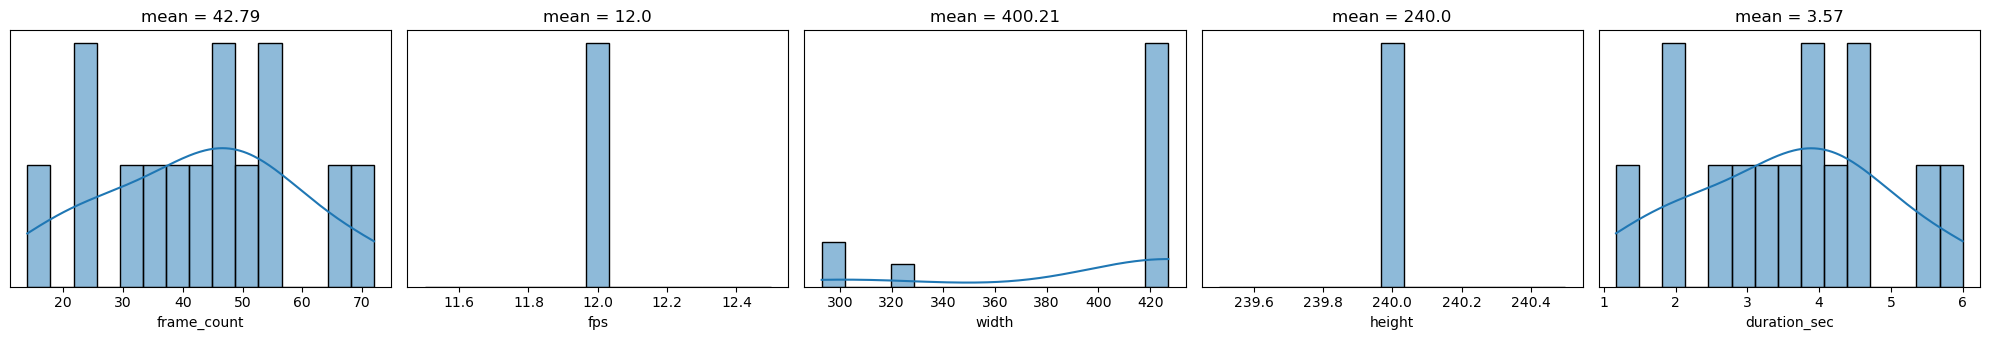

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
cols = ["frame_count", "fps",  "width", "height", "duration_sec"]

for ax, col in zip(axes, cols):    
    sns.histplot(data=df, x=col, ax=ax, kde=True, bins=15).set_title(f"mean = {round(df[col].mean(), 2)}")
    ax.yaxis.set_visible(False)

plt.tight_layout()
plt.show()

In [12]:
ssv2_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2/clips/"
video_files = list(Path(ssv2_path).glob("*.webm"))  # SSv2 is typically .webm or .mp4
len(video_files)

220847

In [16]:
import random
random.sample(video_files, 3)

[PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2/clips/27962.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2/clips/40472.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2/clips/36143.webm')]

In [17]:
stats_list = []

# Scan metadata
for video_file in tqdm(random.sample(video_files, 20000), desc="Scanning videos"):
    meta = get_video_metadata(video_file)
    stats_list.append(meta)

# Create DataFrame for analysis
df = pd.DataFrame(stats_list)
print(df.describe())

Scanning videos: 100%|██████████| 20000/20000 [06:35<00:00, 50.52it/s] 


           fps   frame_count         width   height  aspect_ratio  \
count  20000.0  20000.000000  20000.000000  20000.0  20000.000000   
mean      12.0     45.858300    393.104500    240.0      1.637843   
std        0.0     12.615949     48.815204      0.0      0.204923   
min       12.0      8.000000    135.000000    240.0      0.560000   
25%       12.0     36.000000    360.000000    240.0      1.500000   
50%       12.0     46.000000    427.000000    240.0      1.780000   
75%       12.0     56.000000    427.000000    240.0      1.780000   
max       12.0     86.000000    480.000000    240.0      2.000000   

       duration_sec  
count  20000.000000  
mean       3.821530  
std        1.051322  
min        0.670000  
25%        3.000000  
50%        3.830000  
75%        4.670000  
max        7.170000  


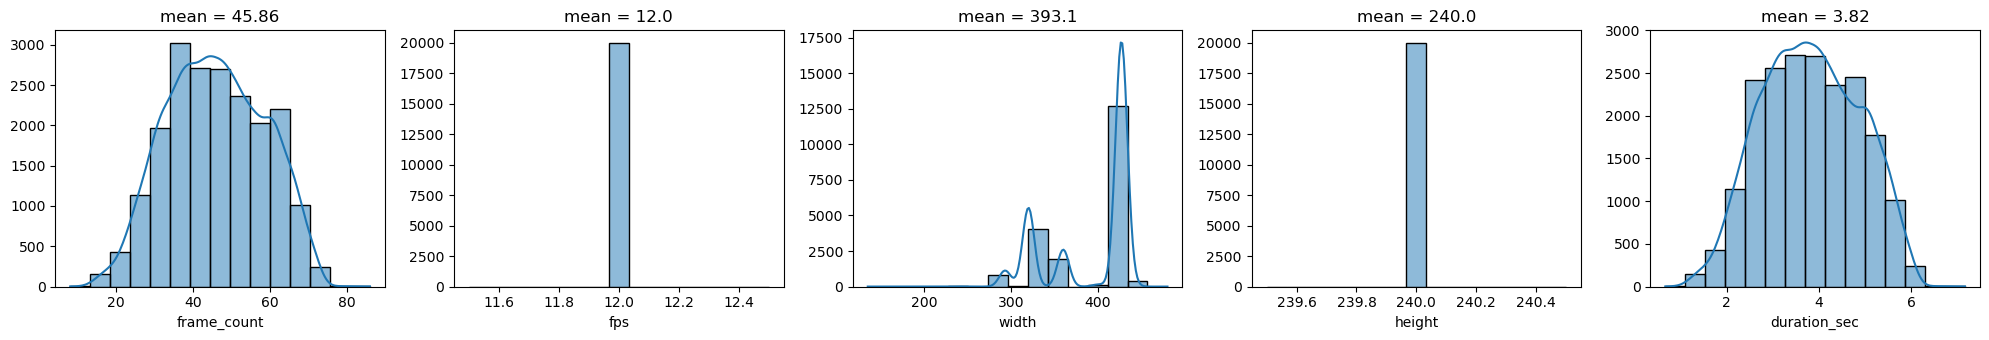

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
cols = ["frame_count", "fps",  "width", "height", "duration_sec"]

for ax, col in zip(axes, cols):    
    sns.histplot(data=df, x=col, ax=ax, kde=True, bins=15).set_title(f"mean = {round(df[col].mean(), 2)}")
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

# ek100

In [ ]:
# from train.txt
videos = [
"P01_01_0.mp4", # 3
"P01_01_1.mp4", # 6
"P01_01_100.mp4", # 0
"P01_01_104.mp4", # 1
"P01_01_106.mp4", # 5
"P01_01_107.mp4", # 4
"P01_01_110.mp4", # 1
"P01_01_111.mp4", # 3
"P01_01_118.mp4", # 10
"P01_01_12.mp4", # 1
"P01_01_122.mp4", # 5
"P01_01_123.mp4", # 4
"P01_01_125.mp4", # 10
"P01_01_130.mp4", # 59
"P01_01_131.mp4", # 77
"P01_01_136.mp4", # 13
"P01_01_145.mp4", # 23
"P01_01_147.mp4", # 9
"P01_01_148.mp4", # 38
"P01_01_190.mp4", # 7
"P01_01_197.mp4", # 13
"P01_01_205.mp4", # 28
"P01_01_222.mp4", # 17
"P01_01_223.mp4", # 10
"P01_01_236.mp4", # 12
"P01_01_259.mp4", # 60
"P01_01_270.mp4", # 72
"P01_01_272.mp4", # 16
"P01_01_277.mp4", # 37
]

for vid in videos:
    1
    # os.system(f"cp {ek100_path}/clips/{vid} ./clips_ek100/")


In [21]:
ek100_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/epic_kitchens_100/clips/"
video_files = list(Path(ek100_path).glob("*.mp4"))
len(video_files)

89977

In [22]:
stats_list = []

# Scan metadata
for video_file in tqdm(random.sample(video_files, 20000), desc="Scanning videos"):
    meta = get_video_metadata(video_file)
    stats_list.append(meta)

# Create DataFrame for analysis
df = pd.DataFrame(stats_list)
print(df.describe())

Scanning videos: 100%|██████████| 20000/20000 [04:42<00:00, 70.86it/s] 


                fps   frame_count         width   height  aspect_ratio  \
count  20000.000000  20000.000000  20000.000000  20000.0  20000.000000   
mean      54.324000    171.361500    683.957000    384.0      1.779888   
std        4.954215    299.839574      2.719287      0.0      0.007114   
min       50.000000     11.000000    512.000000    384.0      1.330000   
25%       50.000000     53.000000    684.000000    384.0      1.780000   
50%       50.000000     87.000000    684.000000    384.0      1.780000   
75%       60.000000    172.000000    684.000000    384.0      1.780000   
max       60.000000  14858.000000    684.000000    384.0      1.780000   

       duration_sec  
count  20000.000000  
mean       3.107490  
std        5.476555  
min        0.220000  
25%        1.000000  
50%        1.600000  
75%        3.120000  
max      297.160000  


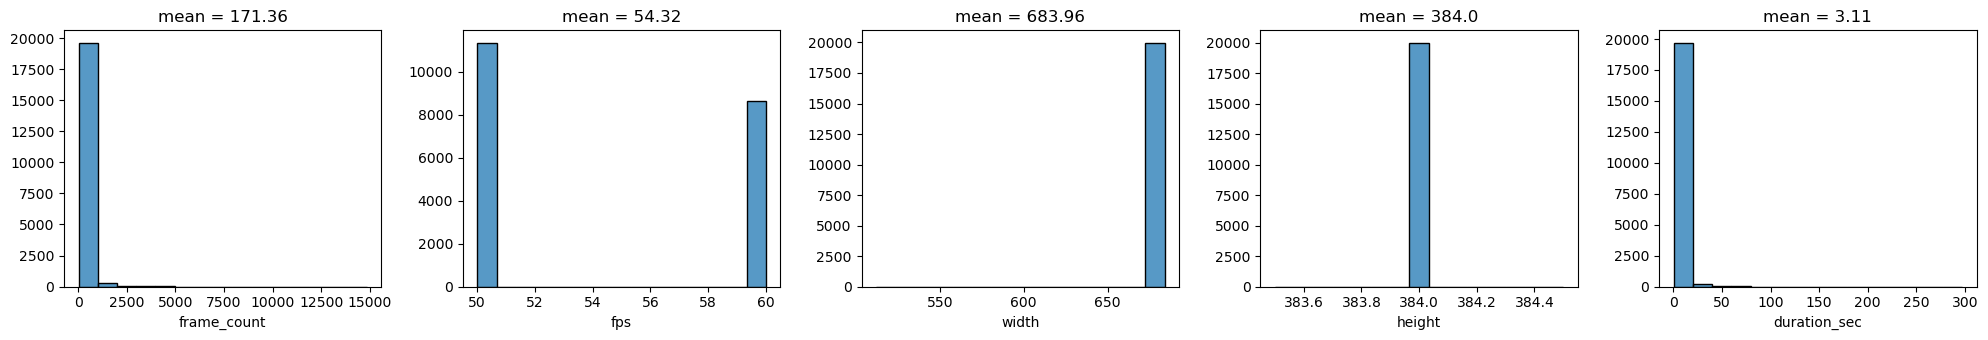

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
cols = ["frame_count", "fps",  "width", "height", "duration_sec"]

for ax, col in zip(axes, cols):    
    sns.histplot(data=df, x=col, ax=ax, bins=15).set_title(f"mean = {round(df[col].mean(), 2)}")
    ax.set_ylabel('')
    
plt.tight_layout()
plt.show()